## Handling Mixed Data

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('DataSets/titanic_updated.csv')
df.head()

,Cabin,Ticket,number,Survived
0,NaN,A/5 21171,5,0
1,C85,PC 17599,3,1
2,NaN,STON/O2. 3101282,6,1
3,C123,113803,3,1
4,NaN,373450,A,0


In [3]:
df['number'].unique()
#A means Alone

<StringArray>
['5', '3', '6', 'A', '2', '1', '4']
Length: 7, dtype: str

In [4]:
df['number'].nunique()

7

#### Numerical and Categorical Data together in different cell

Text(0.5, 1.0, 'Passengers travelling with')

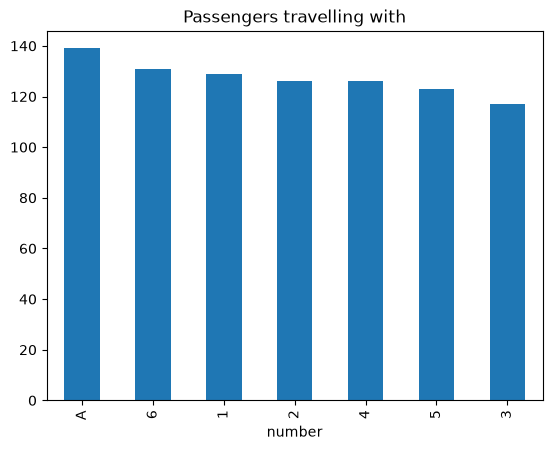

In [5]:
fig = df['number'].value_counts().plot.bar()
fig.set_title('Passengers travelling with')

In [6]:
# extract numerical part and put it in a new column in dataframe
df['number_numerical'] = pd.to_numeric(df["number"],errors='coerce')

#pd.to_numeric() -> Attempts to convert values into numbers.
#errors='coerce' -> if conversion fails → put NaN



# extract categorical part
df['number_categorical'] = np.where(df['number_numerical'].isnull(),df['number'],np.nan)
#df['number_numerical'].isnull() -> checks which rows became NaN
#np.where(condition, if_true, if_false) -> IF condition is True -> true_value, ELSE-> use false_value
#in hindi new column check kar raha ki kya value NAN hai agar haa toh matlab original column me categorical data aur usi ko likh do warna Nan lilh do

In [7]:
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical
0,NaN,A/5 21171,5,0,5.0,NaN
1,C85,PC 17599,3,1,3.0,NaN
2,NaN,STON/O2. 3101282,6,1,6.0,NaN
3,C123,113803,3,1,3.0,NaN
4,NaN,373450,A,0,NaN,A


#### Numerical and Categorical Data together in same cell

In [8]:
df['Cabin'].unique()

<StringArray>
[          nan,         'C85',        'C123',         'E46',          'G6',
        'C103',         'D56',          'A6', 'C23 C25 C27',         'B78',
 ...
        'B102',         'B69',         'E49',         'C47',         'D28',
         'E17',         'A24',         'C50',         'B42',        'C148']
Length: 148, dtype: str

In [9]:
df['Cabin'].nunique()

147

In [10]:
df['Ticket'].unique()

<StringArray>
[       'A/5 21171',         'PC 17599', 'STON/O2. 3101282',
           '113803',           '373450',           '330877',
            '17463',           '349909',           '347742',
           '237736',
 ...
           '349212',           '349217',           '349257',
             '7552', 'C.A./SOTON 34068',  'SOTON/OQ 392076',
           '211536',           '112053',           '111369',
           '370376']
Length: 681, dtype: str

In [11]:
df['Ticket'].nunique()

681

In [12]:
# captures the first letter
df['cabin_cat'] = df['Cabin'].str[0]

# captures numerical part (VERY IMPORTANT)
df['cabin_num'] = df['Cabin'].str.extract('(\d+)') 


df.head()

<>:5: SyntaxWarning: invalid escape sequence '\d'
<>:5: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Akshat\AppData\Local\Temp\ipykernel_14248\2402664936.py:5: SyntaxWarning: invalid escape sequence '\d'
  df['cabin_num'] = df['Cabin'].str.extract('(\d+)')


,Cabin,Ticket,number,Survived,number_numerical,number_categorical,cabin_cat,cabin_num
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN
1,C85,PC 17599,3,1,3.0,NaN,C,85
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN
3,C123,113803,3,1,3.0,NaN,C,123
4,NaN,373450,A,0,NaN,A,NaN,NaN


In [13]:
# extract the last bit of ticket as number
df['ticket_num'] = df['Ticket'].apply(lambda s: s.split()[-1])
df['ticket_num'] = pd.to_numeric(df['ticket_num'],
                                   errors='coerce',
                                   downcast='integer')

# extract the first part of ticket as category
df['ticket_cat'] = df['Ticket'].apply(lambda s: s.split()[0])
df['ticket_cat'] = np.where(df['ticket_cat'].str.isdigit(), np.nan,
                              df['ticket_cat'])

df.head(5)

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,cabin_cat,cabin_num,ticket_num,ticket_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN,21171.0,A/5
1,C85,PC 17599,3,1,3.0,NaN,C,85,17599.0,PC
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN,3101282.0,STON/O2.
3,C123,113803,3,1,3.0,NaN,C,123,113803.0,NaN
4,NaN,373450,A,0,NaN,A,NaN,NaN,373450.0,NaN


## Handling DateTime Variable

In [14]:
date = pd.read_csv('DataSets/orders.csv')[['date']]

In [15]:
print(date.info())
date.head(3)

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   date    1000 non-null   str  
dtypes: str(1)
memory usage: 7.9 KB
None


,date
0,2019-12-10
1,2018-08-15
2,2018-10-23


### Working with Dates

In [16]:
# Converting to datetime datatype
date['date'] = pd.to_datetime(date['date'])

date['date_year'] = date['date'].dt.year
date['date_month_no'] = date['date'].dt.month
date['date_month_name'] = date['date'].dt.month_name()
date['date_day'] = date['date'].dt.day
date['date_dow'] = date['date'].dt.dayofweek
date['date_dow_name'] = date['date'].dt.day_name()
date['quarter'] = date['date'].dt.quarter


#No of weeks in a year
date['date_week'] = date['date'].dt.isocalendar().week

# is semester ie first half of the year
date['semester'] = np.where(date['quarter'].isin([1,2]), 1, 2)


# is weekend?
date['date_is_weekend'] = np.where(date['date_dow_name'].isin(['Sunday', 'Saturday']), 1,0)
#1 is put and 0 is don't put. It is True and false value parameter of numpy where function

In [17]:
date.head(8)

,date,date_year,date_month_no,date_month_name,date_day,date_dow,date_dow_name,quarter,date_week,semester,date_is_weekend
0,2019-12-10,2019,12,December,10,1,Tuesday,4,50,2,0
1,2018-08-15,2018,8,August,15,2,Wednesday,3,33,2,0
2,2018-10-23,2018,10,October,23,1,Tuesday,4,43,2,0
3,2019-08-17,2019,8,August,17,5,Saturday,3,33,2,1
4,2019-01-06,2019,1,January,6,6,Sunday,1,1,1,1
5,2018-08-23,2018,8,August,23,3,Thursday,3,34,2,0
6,2018-11-21,2018,11,November,21,2,Wednesday,4,47,2,0
7,2019-03-27,2019,3,March,27,2,Wednesday,1,13,1,0


### Working with Time

In [18]:
import datetime
time = pd.read_csv('DataSets/messages.csv')[['date']]

In [19]:
print(time.info())
time.head(3)

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   date    1000 non-null   str  
dtypes: str(1)
memory usage: 7.9 KB
None


,date
0,2013-12-15 00:50:00
1,2014-04-29 23:40:00
2,2012-12-30 00:21:00


In [20]:
today = datetime.datetime.today()
today

datetime.datetime(2026, 10, 17, 20, 12, 27, 74472)

In [21]:
# Converting to datetime datatype
time['date'] = pd.to_datetime(time['date'])

In [22]:
time['hour'] = time['date'].dt.hour
time['min'] = time['date'].dt.minute
time['sec'] = time['date'].dt.second
time['time'] = time['date'].dt.time

time['Seconds Passed'] = (( today -date['date']) / np.timedelta64(1, 's'))
time['Minutes Passed'] = ((today - date['date']) / np.timedelta64(1, 'm'))
time['Hours Passed'] = ((today - date['date']) / np.timedelta64(1, 'h'))
time['Time Passed'] = today - date['date']
# time['days_passed'] = ((today - date['date']) / np.timedelta64(1, 'D')) Alternate version of date passed
time['Days Passed'] = (today - date['date']).dt.days
time['Month Passed'] = ((today.year - date['date'].dt.year) * 12 + (today.month - date['date'].dt.month))

#Reason why month has a different method is because they are variable 28/30/31

In [23]:
time.head(8)

,date,hour,min,sec,time,Seconds Passed,Minutes Passed,Hours Passed,Time Passed,Days Passed,Month Passed
0,2013-12-15 00:50:00,0,50,0,00:50:00,2.163319e+08,3.605532e+06,60092.207521,2503 days 20:12:27.074472,2503,82
1,2014-04-29 23:40:00,23,40,0,23:40:00,2.579767e+08,4.299612e+06,71660.207521,2985 days 20:12:27.074472,2985,98
2,2012-12-30 00:21:00,0,21,0,00:21:00,2.520151e+08,4.200252e+06,70004.207521,2916 days 20:12:27.074472,2916,96
3,2014-11-28 00:31:00,0,31,0,00:31:00,2.262679e+08,3.771132e+06,62852.207521,2618 days 20:12:27.074472,2618,86
4,2013-10-26 23:11:00,23,11,0,23:11:00,2.455351e+08,4.092252e+06,68204.207521,2841 days 20:12:27.074472,2841,93
5,2016-03-08 22:52:00,22,52,0,22:52:00,2.572855e+08,4.288092e+06,71468.207521,2977 days 20:12:27.074472,2977,98
6,2014-02-18 00:23:00,0,23,0,00:23:00,2.495095e+08,4.158492e+06,69308.207521,2887 days 20:12:27.074472,2887,95
7,2012-11-23 01:10:00,1,10,0,01:10:00,2.386231e+08,3.977052e+06,66284.207521,2761 days 20:12:27.074472,2761,91


## Handling Missing Data (Important)

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1) Complete Case Analysis

In [25]:
df = pd.read_csv('DataSets/data_science_job.csv')
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [26]:
df.shape

(19158, 13)

In [27]:
df.isnull().sum()

enrollee_id                  0
city                         0
city_development_index     479
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
training_hours             766
target                       0
dtype: int64

In [28]:
#percentage of missing value (IMPORTANT)
df.isnull().mean()*100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [29]:
#Take columns where missing data is less than 5% and missing data exists
cols = [var for var in df.columns if df[var].isnull().mean() < 0.05 and df[var].isnull().mean() > 0]
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [30]:
df[cols].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
14472,0.897,Part time course,Graduate,3.0,20.0
5080,0.698,no_enrollment,Graduate,9.0,130.0
6358,0.884,no_enrollment,Masters,1.0,45.0
5170,0.897,no_enrollment,Masters,3.0,59.0
25,0.855,no_enrollment,High School,4.0,22.0


In [31]:
#amout of data that will be left after dropping missing rows
len(df[cols].dropna()) / len(df)

0.8968577095730244

In [32]:
new_df = df[cols].dropna()
df.shape, new_df.shape

((19158, 13), (17182, 5))

Text(0.5, 1.0, 'City development index after CCA')

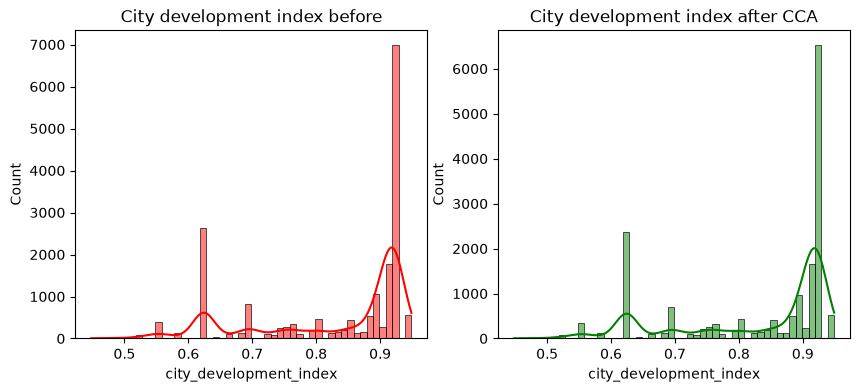

In [33]:
fig = plt.figure(figsize=(10,4))

# original data
plt.subplot(121)
sns.histplot(df['city_development_index'],bins=50, color='red', kde=True)
plt.title('City development index before')

# 
plt.subplot(122)
sns.histplot(new_df['city_development_index'],bins=50,color='green', kde=True)
plt.title('City development index after CCA')

In [34]:
#These graph shows that data missing was missing completely at random as distribution does not change after CCA

In [35]:
# percentage of observations per category, original data
temp = pd.concat([df['enrolled_university'].value_counts() / len(df),

# percentage of observations per category, cca data
new_df['enrolled_university'].value_counts() / len(new_df)], axis=1)

# add column names
temp.columns = ['original', 'cca']

temp

,original,cca
enrolled_university,,
no_enrollment,0.721213,0.735188
Full time course,0.196106,0.200733
Part time course,0.062533,0.064079


In [36]:
# frequency of each category value is same means missing data was random

### 2) Imputation

### i) On Numerical Data

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

#### a) Mean/Median

In [38]:
df = pd.read_csv('DataSets/titanic_toy.csv')
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [39]:
df.isnull().mean()*100

Age         19.865320
Fare         5.050505
Family       0.000000
Survived     0.000000
dtype: float64

In [40]:
X = df.drop(columns=['Survived'])
y = df['Survived']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

X_train.shape, X_test.shape

((712, 3), (179, 3))

In [41]:
X_train.isnull().mean()*100

Age       20.786517
Fare       5.056180
Family     0.000000
dtype: float64

In [42]:
#Finding mean and median for imputation
mean_age = X_train['Age'].mean()
median_age = X_train['Age'].median()

mean_fare = X_train['Fare'].mean()
median_fare = X_train['Fare'].median()

mean_age, median_age, mean_fare, median_fare

(np.float64(29.78590425531915),
 np.float64(28.75),
 np.float64(32.61759689349112),
 np.float64(14.4583))

In [43]:
# Imputating missing values with mean and median and putting them in new columns
X_train['Age_median'] = X_train['Age'].fillna(median_age)
X_train['Age_mean'] = X_train['Age'].fillna(mean_age)

X_train['Fare_median'] = X_train['Fare'].fillna(median_fare)
X_train['Fare_mean'] = X_train['Fare'].fillna(mean_fare)

In [44]:
X_train.sample(5)

,Age,Fare,Family,Age_median,Age_mean,Fare_median,Fare_mean
440,45.0,26.2500,2,45.00,45.000000,26.2500,26.2500
714,52.0,13.0000,0,52.00,52.000000,13.0000,13.0000
223,NaN,7.8958,0,28.75,29.785904,7.8958,7.8958
837,NaN,8.0500,0,28.75,29.785904,8.0500,8.0500
420,NaN,7.8958,0,28.75,29.785904,7.8958,7.8958


In [45]:
print('Original Age variable variance: ', X_train['Age'].var())
print('Age Variance after median imputation: ', X_train['Age_median'].var())
print('Age Variance after mean imputation: ', X_train['Age_mean'].var())

print('Original Fare variable variance: ', X_train['Fare'].var())
print('Fare Variance after median imputation: ', X_train['Fare_median'].var())
print('Fare Variance after mean imputation: ', X_train['Fare_mean'].var())

Original Age variable variance:  204.34951339046142
Age Variance after median imputation:  161.98956633460548
Age Variance after mean imputation:  161.81262452718676
Original Fare variable variance:  2448.1979137063163
Fare Variance after median imputation:  2340.09102197536
Fare Variance after mean imputation:  2324.2385256705534


In [46]:
# Applying mean/median decreases the variance of the original data

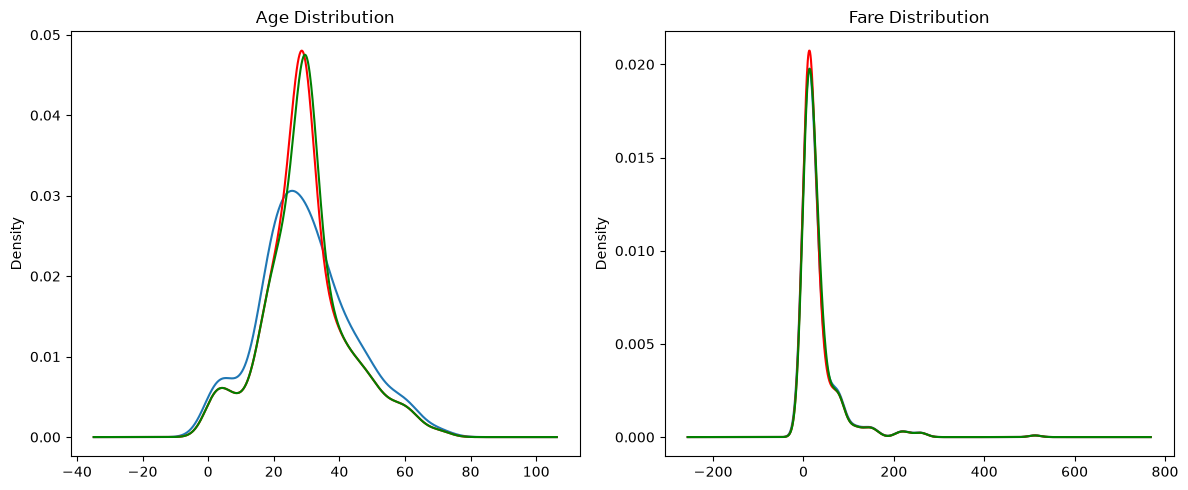

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
# OLD Syntax
# fig = plt.figure(figsize=(12,5))
# ax1 = fig.add_subplot(121)
# ax2 = fig.add_subplot(122)

#AGE
X_train['Age'].plot(kind='kde', ax=axes[0], label='Original')

X_train['Age_median'].plot(kind='kde', ax=axes[0], color='red', label='Median')

X_train['Age_mean'].plot(kind='kde', ax=axes[0], color='green', label='Mean')

axes[0].set_title('Age Distribution')


#FARE
X_train['Fare'].plot(kind='kde', ax=axes[1], label='Original')

X_train['Fare_median'].plot(kind='kde', ax=axes[1], color='red', label='Median')

X_train['Fare_mean'].plot(kind='kde', ax=axes[1], color='green', label='Mean')

axes[1].set_title('Fare Distribution')

plt.tight_layout()
plt.show()

In [48]:
#This graphically shows that age is not fine but fare is ok with Mean/Meadian imputatio

In [49]:
# Checking covariance ie its interaction with other columns. It should not change much
X_train.cov()

,Age,Fare,Family,Age_median,Age_mean,Fare_median,Fare_mean
Age,204.349513,70.719262,-6.498901,204.349513,204.349513,64.858859,66.665205
Fare,70.719262,2448.197914,17.258917,57.957599,55.603719,2448.197914,2448.197914
Family,-6.498901,17.258917,2.735252,-5.112563,-5.146106,16.476305,16.385048
Age_median,204.349513,57.957599,-5.112563,161.989566,161.812625,53.553455,55.023037
Age_mean,204.349513,55.603719,-5.146106,161.812625,161.812625,51.358000,52.788341
Fare_median,64.858859,2448.197914,16.476305,53.553455,51.358000,2340.091022,2324.238526
Fare_mean,66.665205,2448.197914,16.385048,55.023037,52.788341,2324.238526,2324.238526


<Axes: >

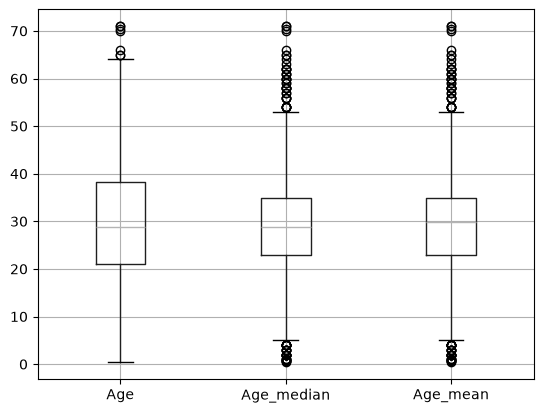

In [50]:
#This is showing introduction of Outliers in Age column
X_train[['Age', 'Age_median', 'Age_mean']].boxplot()

#### Mean/Median Using Sklearn

In [51]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

imputer1 = SimpleImputer(strategy='median')
imputer2 = SimpleImputer(strategy='mean')

# Applying median on age and mean on fare in one go
trf = ColumnTransformer([
    ('imputer1',imputer1,['Age']),
    ('imputer2',imputer2,['Fare'])
],remainder='passthrough')

trf.fit(X_train)

X_train = trf.transform(X_train)
X_test = trf.transform(X_test)

X_train

array([[ 40.    ,  27.7208,   0.    ],
       [  4.    ,  16.7   ,   2.    ],
       [ 47.    ,   9.    ,   0.    ],
       ...,
       [ 71.    ,  49.5042,   0.    ],
       [ 28.75  , 221.7792,   0.    ],
       [ 28.75  ,  25.925 ,   0.    ]], shape=(712, 3))

#### b) Arbritrary Value

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [53]:
df = pd.read_csv('DataSets/titanic_toy.csv')
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [54]:
df.isnull().mean()*100

Age         19.865320
Fare         5.050505
Family       0.000000
Survived     0.000000
dtype: float64

In [55]:
X = df.drop(columns=['Survived'])
y = df['Survived']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [56]:
X_train['Age_99'] = X_train['Age'].fillna(99)
X_train['Age_minus1'] = X_train['Age'].fillna(-1)

X_train['Fare_999'] = X_train['Fare'].fillna(999)
X_train['Fare_minus1'] = X_train['Fare'].fillna(-1)

In [57]:
print('Original Age variable variance: ', X_train['Age'].var())
print('Age Variance after 99 wala imputation: ', X_train['Age_99'].var())
print('Age Variance after -1 wala imputation: ', X_train['Age_minus1'].var())

print('Original Fare variable variance: ', X_train['Fare'].var())
print('Fare Variance after 999 wala imputation: ', X_train['Fare_999'].var())
print('Fare Variance after -1 wala imputation: ', X_train['Fare_minus1'].var())

Original Age variable variance:  204.34951339046142
Age Variance after 99 wala imputation:  951.7275570187188
Age Variance after -1 wala imputation:  318.0896202624488
Original Fare variable variance:  2448.1979137063163
Fare Variance after 999 wala imputation:  47219.202652176304
Fare Variance after -1 wala imputation:  2378.5676784883494


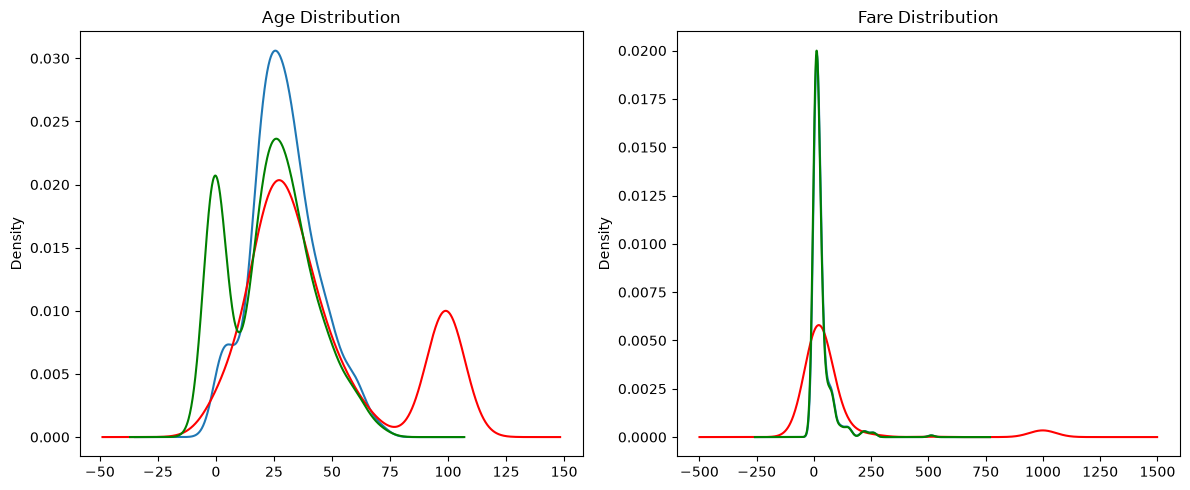

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

#AGE
X_train['Age'].plot(kind='kde', ax=axes[0], label='Original')

X_train['Age_99'].plot(kind='kde', ax=axes[0], color='red', label='99')

X_train['Age_minus1'].plot(kind='kde', ax=axes[0], color='green', label='Minus1')

axes[0].set_title('Age Distribution')


#FARE
X_train['Fare'].plot(kind='kde', ax=axes[1], label='Original')

X_train['Fare_999'].plot(kind='kde', ax=axes[1], color='red', label='999')

X_train['Fare_minus1'].plot(kind='kde', ax=axes[1], color='green', label='Minus1')

axes[1].set_title('Fare Distribution')

plt.tight_layout()
plt.show()

#### Arbritrary Value Using SKlearn 

In [59]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

imputer1 = SimpleImputer(strategy='constant',fill_value=99)
imputer2 = SimpleImputer(strategy='constant',fill_value=999)

trf = ColumnTransformer([
    ('imputer1',imputer1,['Age']),
    ('imputer2',imputer2,['Fare'])
],remainder='passthrough')

trf.fit(X_train)

X_train = trf.transform(X_train)
X_test = trf.transform(X_test)

X_train

array([[ 40.    ,  27.7208,   0.    ],
       [  4.    ,  16.7   ,   2.    ],
       [ 47.    ,   9.    ,   0.    ],
       ...,
       [ 71.    ,  49.5042,   0.    ],
       [ 99.    , 221.7792,   0.    ],
       [ 99.    ,  25.925 ,   0.    ]], shape=(712, 3))

#### c) End of Distribution
- Codes are same as Arbritary just value replaces has to be calcuated based on formulas given

### ii) On Categorical Data

#### a) Most Frequent

In [60]:
df = pd.read_csv('DataSets/advanced_housing.csv',usecols=['GarageQual','FireplaceQu','SalePrice'])
df.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [61]:
df.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

<Axes: xlabel='GarageQual'>

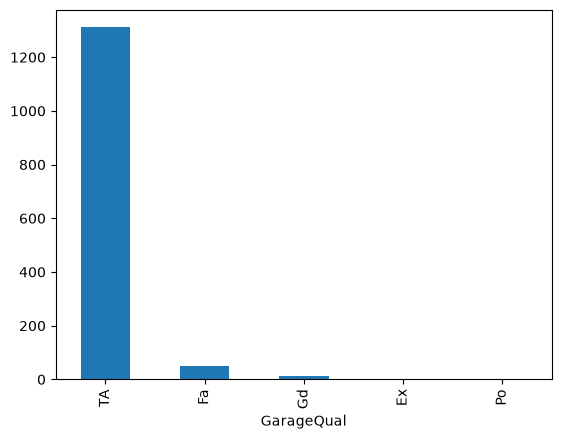

In [62]:
df['GarageQual'].value_counts().plot(kind='bar')

In [63]:
df['GarageQual'].mode()

0    TA
Name: GarageQual, dtype: str

Text(0.5, 1.0, 'GarageQual')

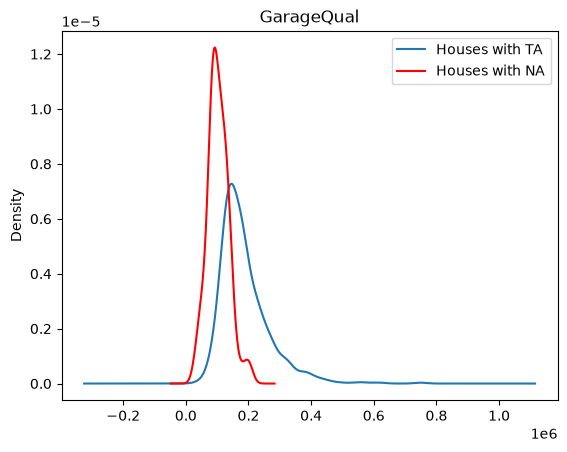

In [64]:
fig = plt.figure()
ax = fig.add_subplot(111)

df[df['GarageQual']=='TA']['SalePrice'].plot(kind='kde', ax=ax)

df[df['GarageQual'].isnull()]['SalePrice'].plot(kind='kde', ax=ax, color='red')

lines, labels = ax.get_legend_handles_labels()
labels = ['Houses with TA', 'Houses with NA']
ax.legend(lines, labels, loc='best')

plt.title('GarageQual')

In [65]:
temp = df[df['GarageQual']=='TA']['SalePrice']

C:\Users\Akshat\AppData\Local\Temp\ipykernel_14248\3591271528.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['GarageQual'].fillna('TA', inplace=True)


<Axes: xlabel='GarageQual'>

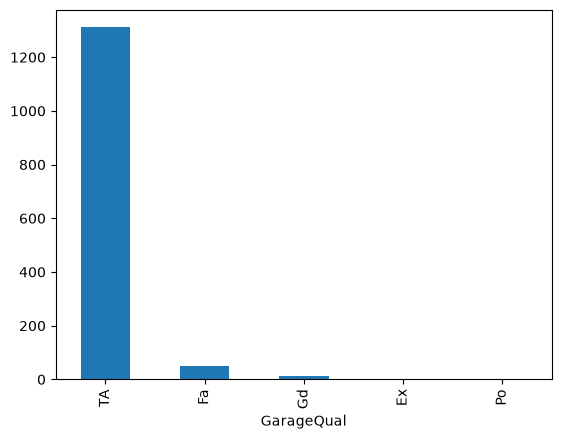

In [66]:
df['GarageQual'].fillna('TA', inplace=True)
df['GarageQual'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'GarageQual')

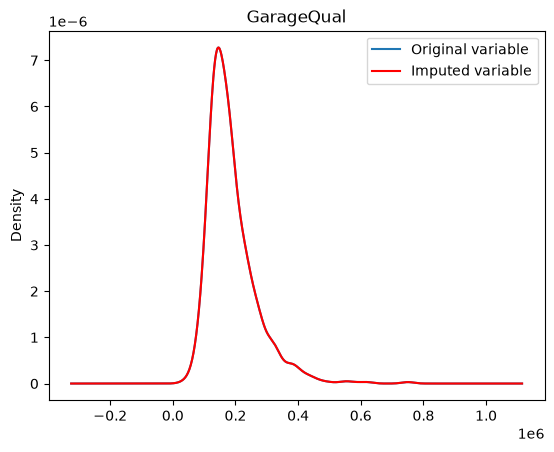

In [67]:
fig = plt.figure()
ax = fig.add_subplot(111)


temp.plot(kind='kde', ax=ax)

# distribution of the variable after imputation
df[df['GarageQual'] == 'TA']['SalePrice'].plot(kind='kde', ax=ax, color='red')

lines, labels = ax.get_legend_handles_labels()
labels = ['Original variable', 'Imputed variable']
ax.legend(lines, labels, loc='best')

# add title
plt.title('GarageQual')

In [68]:
# Garage Quality is mapping with original and imputed because not many missing values and 1st bar is a lot bigger than 2nd bar

<Axes: xlabel='FireplaceQu'>

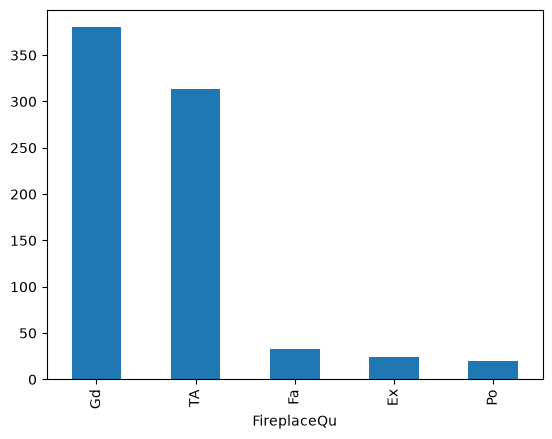

In [69]:
df['FireplaceQu'].value_counts().plot(kind='bar')

In [70]:
df['FireplaceQu'].mode()

0    Gd
Name: FireplaceQu, dtype: str

Text(0.5, 1.0, 'FireplaceQu')

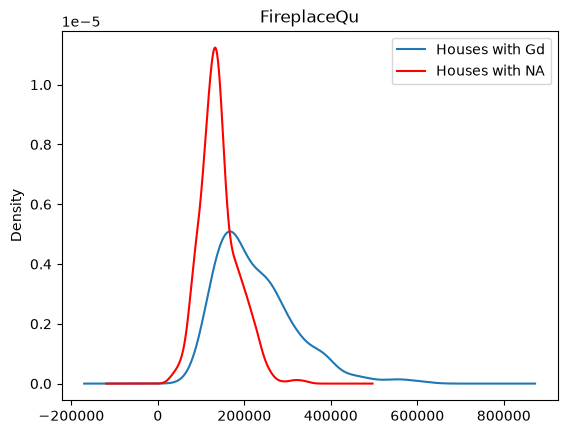

In [71]:
fig = plt.figure()
ax = fig.add_subplot(111)

df[df['FireplaceQu']=='Gd']['SalePrice'].plot(kind='kde', ax=ax)

df[df['FireplaceQu'].isnull()]['SalePrice'].plot(kind='kde', ax=ax, color='red')

lines, labels = ax.get_legend_handles_labels()
labels = ['Houses with Gd', 'Houses with NA']
ax.legend(lines, labels, loc='best')

plt.title('FireplaceQu')

In [72]:
temp = df[df['FireplaceQu']=='Gd']['SalePrice']

C:\Users\Akshat\AppData\Local\Temp\ipykernel_14248\3028501272.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['FireplaceQu'].fillna('Gd', inplace=True)


<Axes: xlabel='FireplaceQu'>

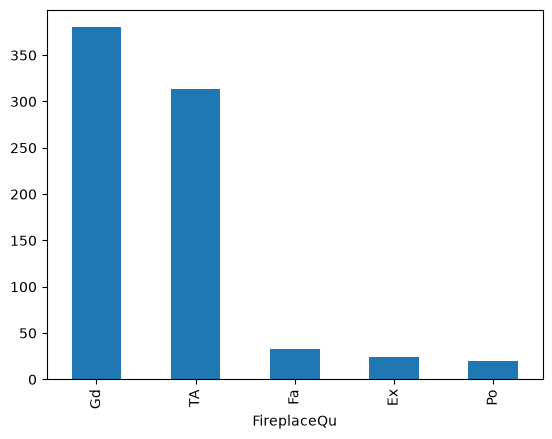

In [73]:
df['FireplaceQu'].fillna('Gd', inplace=True)
df['FireplaceQu'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'FireplaceQu')

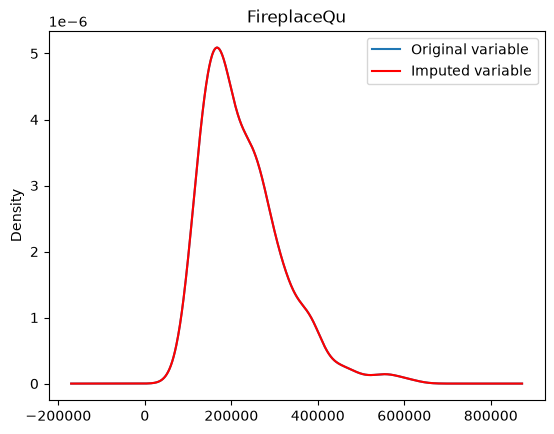

In [74]:
fig = plt.figure()
ax = fig.add_subplot(111)


temp.plot(kind='kde', ax=ax)

# distribution of the variable after imputation
df[df['FireplaceQu'] == 'Gd']['SalePrice'].plot(kind='kde', ax=ax, color='red')

lines, labels = ax.get_legend_handles_labels()
labels = ['Original variable', 'Imputed variable']
ax.legend(lines, labels, loc='best')

# add title
plt.title('FireplaceQu')

In [75]:
# Fireplace Quality is not mapping with original and imputed because many missing values and 1st bar almost same as the 2nd bar

#### b) Replace with Missing

In [76]:
df = pd.read_csv('DataSets/advanced_housing.csv',usecols=['GarageQual','FireplaceQu','SalePrice'])
df.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [77]:
df.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [78]:
df['GarageQual'].fillna('Missing', inplace=True)

C:\Users\Akshat\AppData\Local\Temp\ipykernel_14248\4070582888.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['GarageQual'].fillna('Missing', inplace=True)


0       TA
1       TA
2       TA
3       TA
4       TA
        ..
1455    TA
1456    TA
1457    TA
1458    TA
1459    TA
Name: GarageQual, Length: 1460, dtype: str

Text(0, 0.5, 'Number of houses')

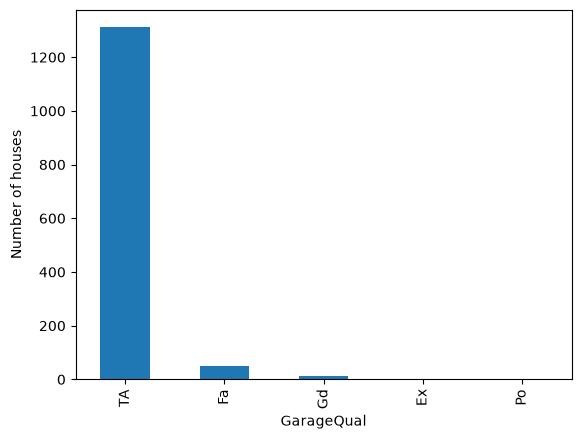

In [79]:
df['GarageQual'].value_counts().sort_values(ascending=False).plot.bar()
plt.xlabel('GarageQual')
plt.ylabel('Number of houses')

#### Missing using SKlearn

In [80]:
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop(columns=['SalePrice']),df['SalePrice'],test_size=0.2)

imputer = SimpleImputer(strategy='constant',fill_value='Missing')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_train)

c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


#### c) Random Number Imputator

In [81]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

In [82]:
df = pd.read_csv('DataSets/titanic.csv',usecols=['Age','Fare','Survived'])
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [83]:
df.isnull().mean() * 100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [84]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

X_train.head()

,Age,Fare,Family
30,40.0,27.7208,0
10,4.0,16.7000,2
873,47.0,9.0000,0
182,9.0,31.3875,6
876,20.0,9.8458,0


In [85]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

#OLD SYNTAX -> X_train['Age_imputed'][X_train['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values
X_train.loc[X_train['Age_imputed'].isnull(),'Age_imputed'] = X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values

#OLD SYNTAX -> X_test['Age_imputed'][X_test['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_test['Age'].isnull().sum()).values
X_test.loc[X_test['Age_imputed'].isnull(),'Age_imputed'] = X_train['Age'].dropna().sample(X_test['Age'].isnull().sum()).values


# X_train['Age_imputed'].isnull()    Gives boolean of whether value is missing or not
#X_train['Age_imputed'][X_train['Age_imputed'].isnull()]    fetches values which have missing value
#X_train['Age'].dropna()    this code drops all missing values
#X_train['Age'].dropna().sample()    sample gives one random value but we need to fill all the missing values
#X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values    this gives us total needed missing values as inside code is just sum of all missing values

In [86]:
# EXTRA STEP FOR CATEGORICAL DATA
# To check if it is changing the frequnecy of data
#temp = pd.concat([X_train['FireplaceQu'].value_counts() / len(X_train['FireplaceQu'].dropna()), X_train['FireplaceQu_imputed'].value_counts() / len(df)],axis=1)

#temp.columns = ['original', 'imputed']
#temp

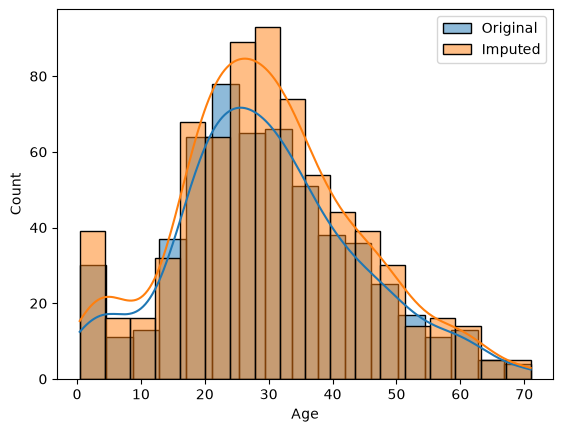

In [87]:
sns.histplot(X_train['Age'],label='Original',kde = True)
sns.histplot(X_train['Age_imputed'],label = 'Imputed',kde = True)

plt.legend()
plt.show()

In [88]:
print('Original variable variance: ', X_train['Age'].var())
print('Variance after random imputation: ', X_train['Age_imputed'].var())

Original variable variance:  204.34951339046142
Variance after random imputation:  203.81728776055246


In [89]:
X_train[['Fare', 'Age', 'Age_imputed']].cov()

,Fare,Age,Age_imputed
Fare,2448.197914,70.719262,44.927816
Age,70.719262,204.349513,204.349513
Age_imputed,44.927816,204.349513,203.817288


In [90]:
# #WRONG AND GPT IS ALSO WRONG


# #for two same fare values and missing age we might get different age because of random which will give different answer for same data this should not happen which is why  we can use this
# #sampled_value = X_train['Age'].dropna().sample(1, random_state=int(observation['Fare'])) No longer working because we are using random_state which is not allowed in sample function

# for index, observation in X_train.iterrows():
#     if pd.isnull(observation['Age']):
#         sampled_value = X_train['Age'].dropna().sample(
#             1,
#             random_state=int(observation['Fare'])
#         ).iloc[0]

#         X_train.loc[index, 'Age'] = sampled_value

### Missing Data Indicator

In [91]:
from sklearn.impute import MissingIndicator,SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [92]:
df = pd.read_csv('DataSets/titanic.csv',usecols=['Age','Fare','Survived'])
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [93]:
#Without missing Indicator
X = df.drop(columns=['Survived'])
y = df['Survived']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

si = SimpleImputer()
X_train_trf = si.fit_transform(X_train)
X_test_trf = si.transform(X_test)

clf = LogisticRegression()
clf.fit(X_train_trf,y_train)

y_pred = clf.predict(X_test_trf)

print("Without missing Indicator ",accuracy_score(y_test,y_pred))


#With missing Indicator
mi = MissingIndicator()

mi.fit(X_train)

X_train_missing = mi.transform(X_train)
X_test_missing = mi.transform(X_test)

X_train['Age_NA'] = X_train_missing
X_test['Age_NA'] = X_test_missing

#si = SimpleImputer(add_indicator=True)    If this is written then you you don't have to right above code
si = SimpleImputer()
X_train_trf2 = si.fit_transform(X_train)
X_test_trf2 = si.transform(X_test)

clf = LogisticRegression()
clf.fit(X_train_trf2,y_train)

y_pred = clf.predict(X_test_trf2)

print("With missing Indicator ",accuracy_score(y_test,y_pred))

Without missing Indicator  0.6145251396648045
With missing Indicator  0.6312849162011173


#### Automatically Select Imputator(Left)

### KNN Imputor

In [94]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

from sklearn.impute import KNNImputer,SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score

In [95]:
df = pd.read_csv('DataSets/titanic.csv',usecols=['Age','Pclass','Fare','Survived'])
df.head()

,Survived,Pclass,Age,Fare
0,0,3,22.0,7.2500
1,1,1,38.0,71.2833
2,1,3,26.0,7.9250
3,1,1,35.0,53.1000
4,0,3,35.0,8.0500


In [96]:
df.isnull().mean() * 100

Survived     0.00000
Pclass       0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [97]:
X = df.drop(columns=['Survived'])
y = df['Survived']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

knn = KNNImputer(n_neighbors=3,weights='distance')
# for k=2 R1->NA, R2->x(value), R3->y, R1-R2->X, R1-R3->X(Distance)
# in uniform we do x+y/2
# in distance we do [(1/X)*x + (1/Y)*y]/2 {In this closer neighbour is given more weightage}

X_train_trf = knn.fit_transform(X_train)
X_test_trf = knn.transform(X_test)

lr = LogisticRegression()
lr.fit(X_train_trf,y_train)

y_pred = lr.predict(X_test_trf)

print(accuracy_score(y_test,y_pred))

0.7039106145251397


### Iterative Imputor/ MICE Algorithm

In [98]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression

In [99]:
df = pd.read_csv('DataSets/Startups.csv')[['R&D Spend','Administration','Marketing Spend','Profit']]
df.head()

,R&D Spend,Administration,Marketing Spend,Profit
0,165349.20,136897.80,471784.10,192261.83
1,162597.70,151377.59,443898.53,191792.06
2,153441.51,101145.55,407934.54,191050.39
3,144372.41,118671.85,383199.62,182901.99
4,142107.34,91391.77,366168.42,166187.94


In [100]:
df = df/10000
df.head()

,R&D Spend,Administration,Marketing Spend,Profit
0,16.534920,13.689780,47.178410,19.226183
1,16.259770,15.137759,44.389853,19.179206
2,15.344151,10.114555,40.793454,19.105039
3,14.437241,11.867185,38.319962,18.290199
4,14.210734,9.139177,36.616842,16.618794


In [101]:
df = np.round(df)
df.head()

,R&D Spend,Administration,Marketing Spend,Profit
0,17.0,14.0,47.0,19.0
1,16.0,15.0,44.0,19.0
2,15.0,10.0,41.0,19.0
3,14.0,12.0,38.0,18.0
4,14.0,9.0,37.0,17.0


In [102]:
np.random.seed(9)  #Will always take 9 same random rows
df = df.sample(5)
df

,R&D Spend,Administration,Marketing Spend,Profit
21,8.0,15.0,30.0,11.0
37,4.0,5.0,20.0,9.0
2,15.0,10.0,41.0,19.0
14,12.0,16.0,26.0,13.0
44,2.0,15.0,3.0,7.0


In [103]:
#removed output feature
df = df.iloc[:,0:-1]
df

,R&D Spend,Administration,Marketing Spend
21,8.0,15.0,30.0
37,4.0,5.0,20.0
2,15.0,10.0,41.0
14,12.0,16.0,26.0
44,2.0,15.0,3.0


In [104]:
# Create fake missing values
df.iloc[1,0] = np.nan
df.iloc[3,1] = np.nan
df.iloc[-1,-1] = np.nan
df.head()

,R&D Spend,Administration,Marketing Spend
21,8.0,15.0,30.0
37,NaN,5.0,20.0
2,15.0,10.0,41.0
14,12.0,NaN,26.0
44,2.0,15.0,NaN


In [105]:
# Step 1 - Impute all missing values with mean of respective col

df0 = pd.DataFrame()

df0['R&D Spend'] = df['R&D Spend'].fillna(df['R&D Spend'].mean())
df0['Administration'] = df['Administration'].fillna(df['Administration'].mean())
df0['Marketing Spend'] = df['Marketing Spend'].fillna(df['Marketing Spend'].mean())

In [106]:
# 0th Iteration
df0

,R&D Spend,Administration,Marketing Spend
21,8.00,15.00,30.00
37,9.25,5.00,20.00
2,15.00,10.00,41.00
14,12.00,11.25,26.00
44,2.00,15.00,29.25


In [107]:
# Remove the col1 imputed value
df1 = df0.copy()
df1.iloc[1,0] = np.nan
df1

,R&D Spend,Administration,Marketing Spend
21,8.0,15.00,30.00
37,NaN,5.00,20.00
2,15.0,10.00,41.00
14,12.0,11.25,26.00
44,2.0,15.00,29.25


In [108]:
# Use first rest of the rows to build a model and use the missing value row for prediction
X = df1.iloc[[0,2,3,4],1:3]
X

,Administration,Marketing Spend
21,15.00,30.00
2,10.00,41.00
14,11.25,26.00
44,15.00,29.25


In [109]:
#Use col1 as output feature
y = df1.iloc[[0,2,3,4],0]
y

21     8.0
2     15.0
14    12.0
44     2.0
Name: R&D Spend, dtype: float64

In [110]:
#use model to predict value and save it
lr = LinearRegression()
lr.fit(X,y)
predict = lr.predict(df1.iloc[1,1:].values.reshape(1,2))

#fill the missing place with the predicted value
df1.iloc[1,0] = predict

c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [111]:
df1

,R&D Spend,Administration,Marketing Spend
21,8.000000,15.00,30.00
37,23.141587,5.00,20.00
2,15.000000,10.00,41.00
14,12.000000,11.25,26.00
44,2.000000,15.00,29.25


In [112]:
# Remove the col2 imputed value
df1.iloc[3,1] = np.nan

# Use first rest of the rows to build a model and use the missing value row for prediction
X = df1.iloc[[0,1,2,4],[0,2]]
y = df1.iloc[[0,1,2,4],1]

#use model to predict value and save it
lr = LinearRegression()
lr.fit(X,y)
predict = lr.predict(df1.iloc[3,[0,2]].values.reshape(1,2))

#fill the missing place with the predicted value
df1.iloc[3,1] = predict
df1

c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,R&D Spend,Administration,Marketing Spend
21,8.000000,15.000000,30.00
37,23.141587,5.000000,20.00
2,15.000000,10.000000,41.00
14,12.000000,11.063618,26.00
44,2.000000,15.000000,29.25


In [113]:
# Remove the col3 imputed value
df1.iloc[4,-1] = np.nan

# Use first rest of the rows to build a model and use the missing value row for prediction
X = df1.iloc[0:4,0:2]
y = df1.iloc[0:4,-1]

#use model to predict value and save it
lr = LinearRegression()
lr.fit(X,y)
predict = lr.predict(df1.iloc[4,0:2].values.reshape(1,2))

#fill the missing place with the predicted value
df1.iloc[4,-1] = predict
df1

c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,R&D Spend,Administration,Marketing Spend
21,8.000000,15.000000,30.000000
37,23.141587,5.000000,20.000000
2,15.000000,10.000000,41.000000
14,12.000000,11.063618,26.000000
44,2.000000,15.000000,31.601847


In [114]:
#1st Iteration complete

In [115]:
# Subtract 0th iteration from 1st iteration
df1 - df0
df2 = df1.copy()

df2.iloc[1,0] = np.nan
df2
X = df2.iloc[[0,2,3,4],1:3]
y = df2.iloc[[0,2,3,4],0]
lr = LinearRegression()
lr.fit(X,y)
predict = lr.predict(df2.iloc[1,1:].values.reshape(1,2))
df2.iloc[1,0] = predict

df2.iloc[3,1] = np.nan
X = df2.iloc[[0,1,2,4],[0,2]]
y = df2.iloc[[0,1,2,4],1]
lr = LinearRegression()
lr.fit(X,y)
predict = lr.predict(df2.iloc[3,[0,2]].values.reshape(1,2))
df2.iloc[3,1] = predict

df2.iloc[4,-1] = np.nan
X = df2.iloc[0:4,0:2]
y = df2.iloc[0:4,-1]
lr = LinearRegression()
lr.fit(X,y)
predict = lr.predict(df2.iloc[4,0:2].values.reshape(1,2))
df2.iloc[4,-1] = predict

c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\Coding\Artificial Intelligence\Machine Learning\ml_tutorial\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [116]:
df2

,R&D Spend,Administration,Marketing Spend
21,8.000000,15.000000,30.000000
37,23.828703,5.000000,20.000000
2,15.000000,10.000000,41.000000
14,12.000000,11.230737,26.000000
44,2.000000,15.000000,39.390436


In [117]:
df2 - df1

,R&D Spend,Administration,Marketing Spend
21,0.000000,0.000000,0.000000
37,0.687117,0.000000,0.000000
2,0.000000,0.000000,0.000000
14,0.000000,0.167119,0.000000
44,0.000000,0.000000,7.788589


In [118]:
#Now you can keep doing it until the difference reaches 0

## Handling Outliers

### Z-Score Method

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [120]:
df = pd.read_csv('DataSets/placement.csv')
print(df.shape)
df.sample(5)

(1000, 3)


,cgpa,placement_exam_marks,placed
56,6.93,15.0,1
231,6.40,35.0,0
993,6.73,21.0,1
570,7.04,18.0,0
789,6.46,74.0,0


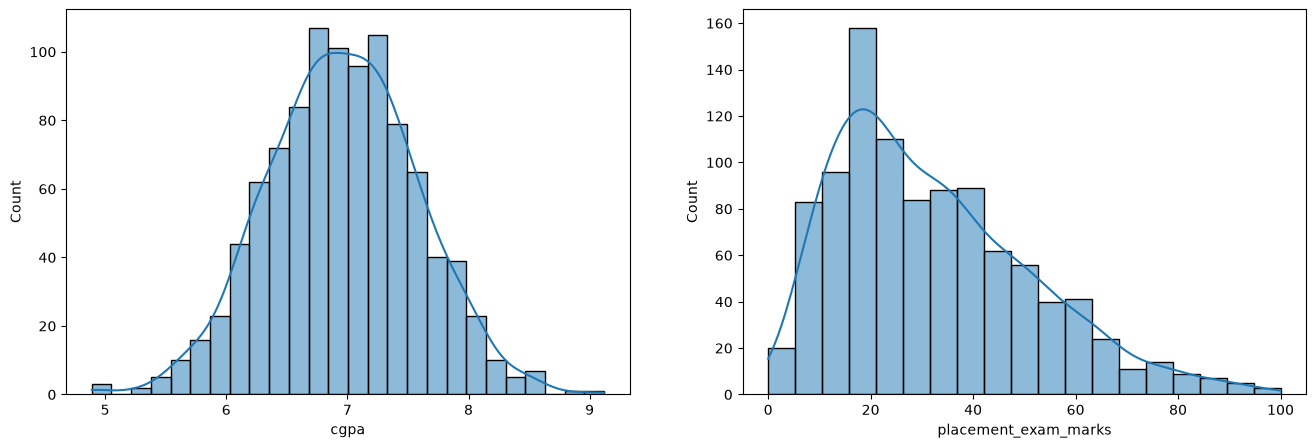

In [121]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.histplot(df['cgpa'], kde=True)

plt.subplot(1,2,2)
sns.histplot(df['placement_exam_marks'], kde=True)

plt.show()

In [122]:
print(df['placement_exam_marks'].skew())
print(df['cgpa'].skew())
print("Mean value of cgpa",df['cgpa'].mean())
print("Std value of cgpa",df['cgpa'].std())
print("Min value of cgpa",df['cgpa'].min())
print("Max value of cgpa",df['cgpa'].max())

# Finding the boundary values
# mean +- 3 std
print("Highest allowed",df['cgpa'].mean() + 3*df['cgpa'].std())
print("Lowest allowed",df['cgpa'].mean() - 3*df['cgpa'].std())

# Finding the outliers
df[(df['cgpa'] > 8.80) | (df['cgpa'] < 5.11)]

0.8356419499466834
-0.014529938929314918
Mean value of cgpa 6.96124
Std value of cgpa 0.6158978751323896
Min value of cgpa 4.89
Max value of cgpa 9.12
Highest allowed 8.808933625397168
Lowest allowed 5.113546374602832


,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


In [123]:
# Trimming (M1)
new_df = df[(df['cgpa'] < 8.80) & (df['cgpa'] > 5.11)]
print(new_df.shape)
new_df.sample

(995, 3)


<bound method NDFrame.sample of      cgpa  placement_exam_marks  placed
0    7.19                  26.0       1
1    7.46                  38.0       1
2    7.54                  40.0       1
3    6.42                   8.0       1
4    7.23                  17.0       0
..    ...                   ...     ...
991  7.04                  57.0       0
992  6.26                  12.0       0
993  6.73                  21.0       1
994  6.48                  63.0       0
998  8.62                  46.0       1

[995 rows x 3 columns]>

In [124]:
# Trimming [Calculating the Zscore] M2
df['cgpa_zscore'] = ( df['cgpa'] - df['cgpa'].mean() ) / ( df['cgpa'].std() )
print (df.head())

new_df = df[(df['cgpa_zscore'] < 3) & (df['cgpa_zscore'] > -3)]
new_df

   cgpa  placement_exam_marks  placed  cgpa_zscore
0  7.19                  26.0       1     0.371425
1  7.46                  38.0       1     0.809810
2  7.54                  40.0       1     0.939701
3  6.42                   8.0       1    -0.878782
4  7.23                  17.0       0     0.436371


,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371
...,...,...,...,...
991,7.04,57.0,0,0.127878
992,6.26,12.0,0,-1.138565
993,6.73,21.0,1,-0.375452
994,6.48,63.0,0,-0.781363


In [125]:
# Capping ie outlier values replaced with boundary of range values
upper_limit = df['cgpa'].mean() + 3*df['cgpa'].std()
lower_limit = df['cgpa'].mean() - 3*df['cgpa'].std()

print(upper_limit)
print(lower_limit)

df['cgpa'] = np.where( df['cgpa']>upper_limit, upper_limit, np.where(df['cgpa']<lower_limit, lower_limit, df['cgpa']))

df['cgpa'].describe()

8.808933625397168
5.113546374602832


count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: cgpa, dtype: float64

### IQR Method

In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [127]:
df = pd.read_csv('DataSets/placement.csv')
print(df.shape)
df.sample(5)

(1000, 3)


,cgpa,placement_exam_marks,placed
220,7.75,16.0,1
825,6.30,23.0,0
805,6.23,13.0,0
668,7.24,47.0,0
445,5.56,10.0,0


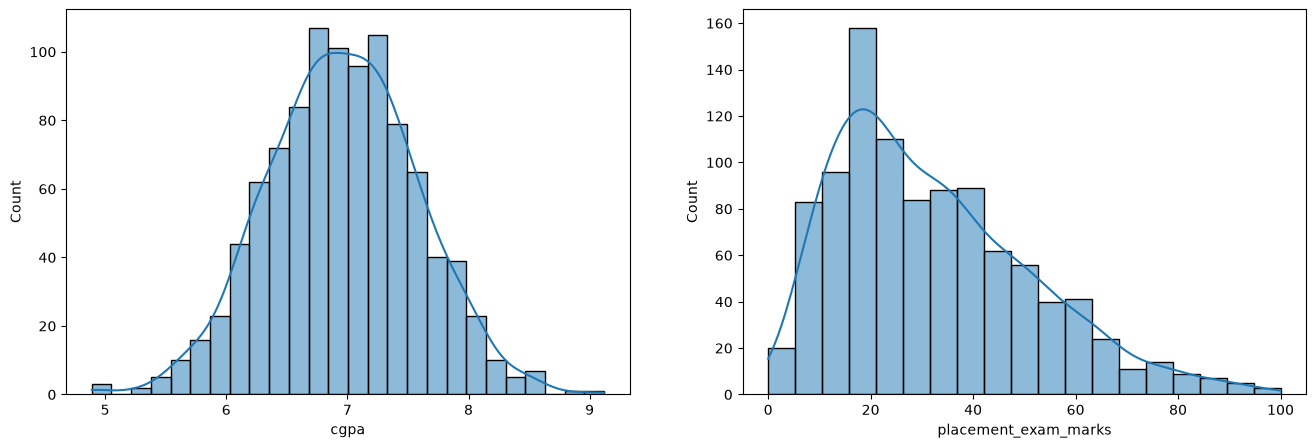

In [128]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.histplot(df['cgpa'], kde=True)

plt.subplot(1,2,2)
sns.histplot(df['placement_exam_marks'], kde=True)

plt.show()

In [129]:
df['placement_exam_marks'].describe()

count    1000.000000
mean       32.225000
std        19.130822
min         0.000000
25%        17.000000
50%        28.000000
75%        44.000000
max       100.000000
Name: placement_exam_marks, dtype: float64

<Axes: ylabel='placement_exam_marks'>

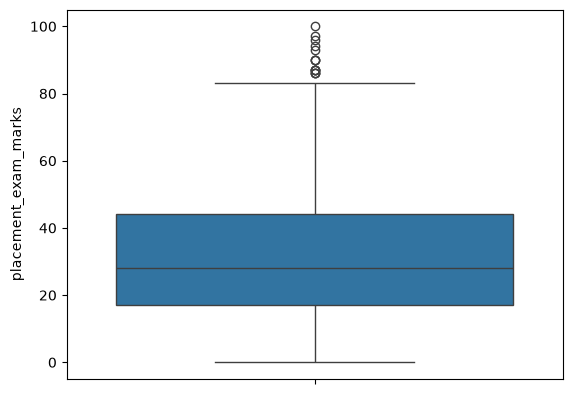

In [130]:
sns.boxplot(df['placement_exam_marks'])

In [131]:
# Finding the IQR, upper and lower limit
percentile25 = df['placement_exam_marks'].quantile(0.25)
percentile75 = df['placement_exam_marks'].quantile(0.75)
iqr = percentile75 - percentile25

print("25th Percentile ",percentile25)
print("75th Percentile ",percentile75)
print("IQR ",iqr)

upper_limit = percentile75 + 1.5 * iqr
lower_limit = percentile25 - 1.5 * iqr
print("Upper limit",upper_limit)
print("Lower limit",lower_limit)

25th Percentile  17.0
75th Percentile  44.0
IQR  27.0
Upper limit 84.5
Lower limit -23.5


In [132]:
#Detection of Outliers
df[( df['placement_exam_marks'] < lower_limit ) | ( df['placement_exam_marks'] > upper_limit ) ]

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


(1000, 3)
(985, 3)


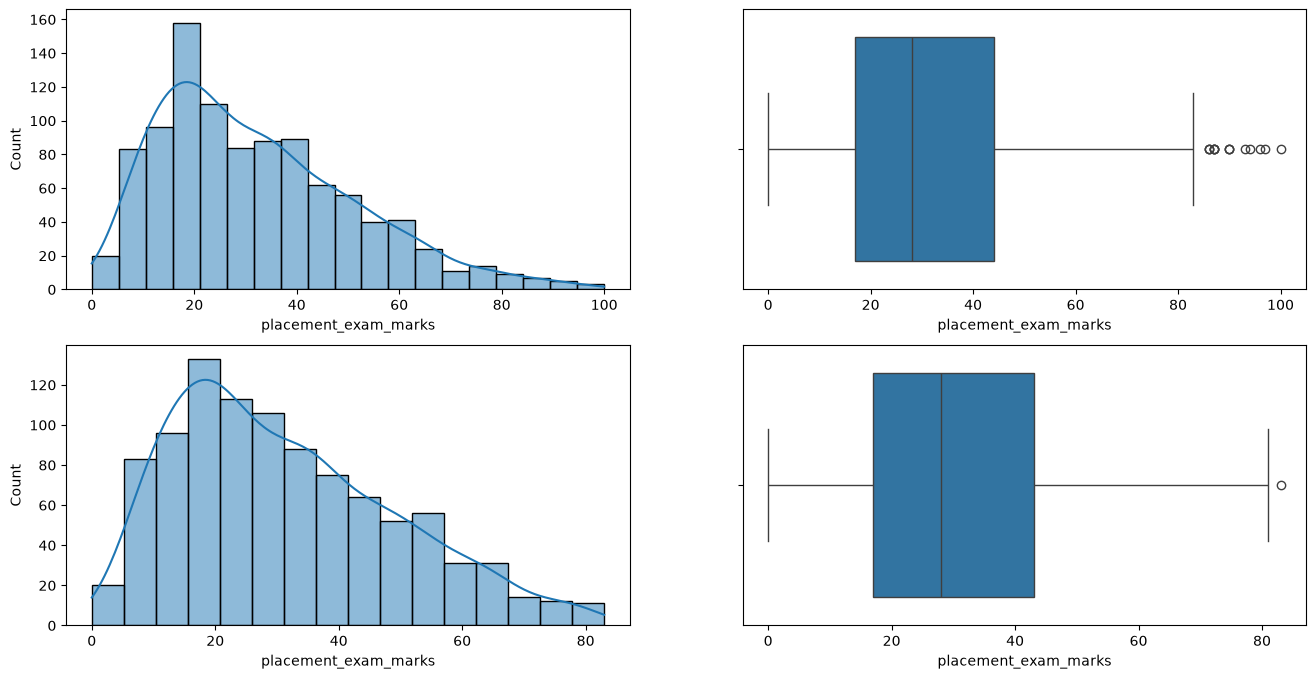

In [133]:
#Trimming
new_df = df[( df['placement_exam_marks'] > lower_limit ) & ( df['placement_exam_marks'] < upper_limit ) ]
print(df.shape)
print(new_df.shape)

# Comparing
plt.figure(figsize=(16,8))
plt.subplot(2,2,1)
sns.histplot(df['placement_exam_marks'], kde=True)

plt.subplot(2,2,2)
sns.boxplot(x=df['placement_exam_marks'])

plt.subplot(2,2,3)
sns.histplot(new_df['placement_exam_marks'], kde=True)

plt.subplot(2,2,4)
sns.boxplot(x=new_df['placement_exam_marks'])

plt.show()

In [134]:
# Capping ie outlier values replaced with boundary of range values
new_df_cap = df.copy()

new_df_cap['placement_exam_marks'] = np.where(new_df_cap['placement_exam_marks'] > upper_limit, upper_limit, np.where(new_df_cap['placement_exam_marks'] < lower_limit, lower_limit, new_df_cap['placement_exam_marks']))

print(df.shape)
print(new_df_cap.shape)

(1000, 3)
(1000, 3)


### Percentile Method

#### Trimming - > NA
#### Capping -> Winsorization

In [135]:
import numpy as np
import pandas as pd
import seaborn as sns

In [136]:
df = pd.read_csv('DataSets/weight-height.csv')
print(df.shape)
df.head()

(10000, 3)


,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [137]:
df['Height'].describe()

count    10000.000000
mean        66.367560
std          3.847528
min         54.263133
25%         63.505620
50%         66.318070
75%         69.174262
max         78.998742
Name: Height, dtype: float64

<Axes: xlabel='Height', ylabel='Count'>

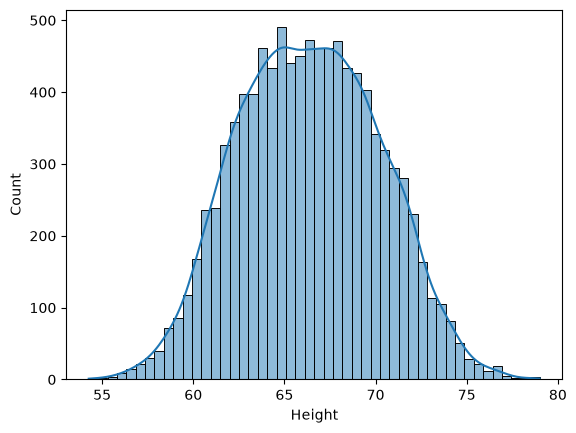

In [138]:
sns.histplot(df['Height'],kde=True)

<Axes: xlabel='Height'>

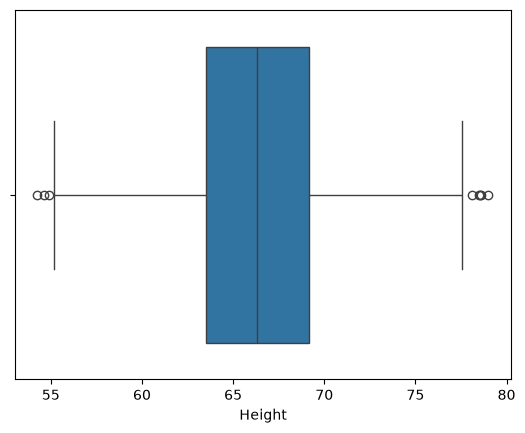

In [139]:
sns.boxplot(x=df['Height'])

In [140]:
upper_limit = df['Height'].quantile(0.99)
lower_limit = df['Height'].quantile(0.01)

print(upper_limit)
print(lower_limit)

#Trimming
new_df = df[(df['Height'] <= upper_limit) & (df['Height'] >= lower_limit)]
new_df['Height'].describe()

74.7857900583366
58.13441158671655


count    9800.000000
mean       66.364366
std         3.645075
min        58.134496
25%        63.577162
50%        66.318070
75%        69.119896
max        74.785714
Name: Height, dtype: float64

<Axes: xlabel='Height', ylabel='Count'>

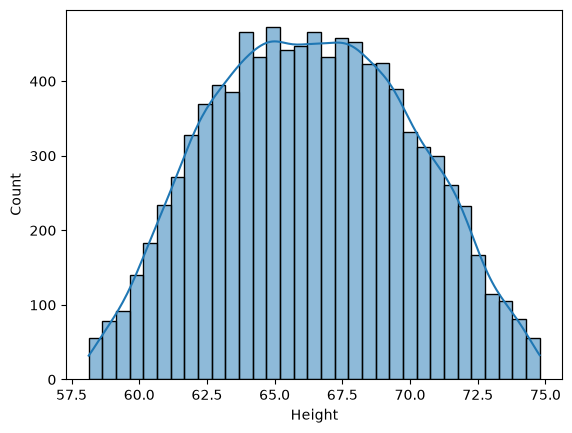

In [141]:
sns.histplot(new_df['Height'], kde=True)

<Axes: ylabel='Height'>

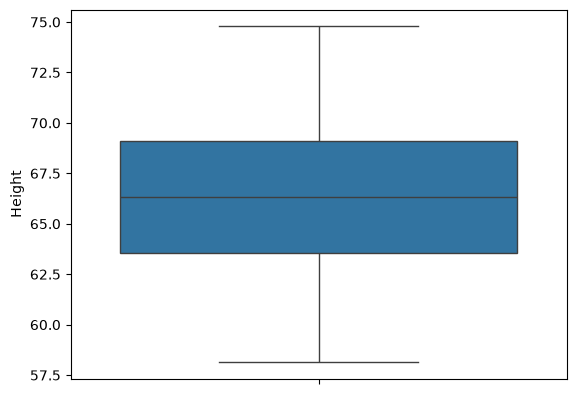

In [142]:
sns.boxplot(new_df['Height'])

<Axes: xlabel='Height', ylabel='Count'>

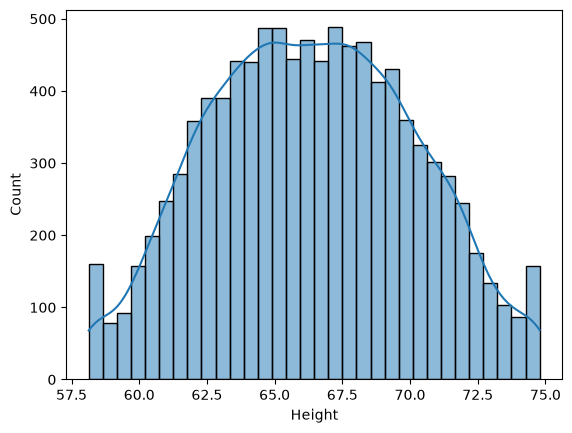

In [143]:
# Capping --> Winsorization
df['Height'] = np.where(df['Height'] >= upper_limit, upper_limit, np.where(df['Height'] <= lower_limit, lower_limit, df['Height']))

sns.histplot(df['Height'],kde=True)

<Axes: xlabel='Height'>

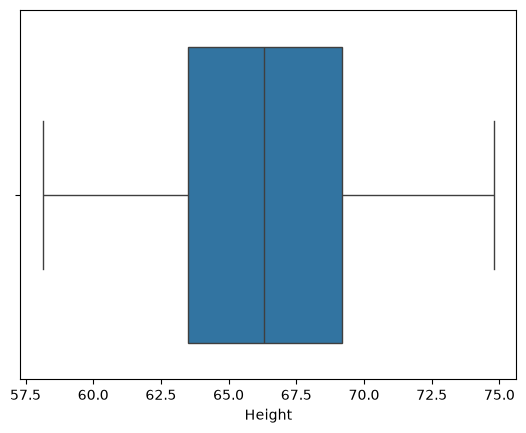

In [144]:
sns.boxplot(x=df['Height'])